# Mô hình 3: Isolation Forest - phát hiện sản phẩm bất thường về giá / giảm giá
**Mục tiêu:** tìm các sản phẩm có giá hoặc mức giảm giá khác biệt đáng kể so với phần còn lại cùng sàn.
**Lưu ý:** kết quả là các điểm *cần xem xét*, không mặc nhiên là lỗi dữ liệu.

**Cột dùng:** gia_ban, gia_goc, so_tien_giam_gia, ty_le_giam_gia (thử thêm so_luong_da_ban để so sánh).
Huấn luyện riêng từng sàn vì mặt bằng giá Tiki và Hasaki khác nhau.

In [1]:
# 1. Thư viện và đọc dữ liệu
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from common import MODELS_DIR, OUTPUT_DIR, load_products, prepare_ml_data, save_metrics, save_results, savefig

FEATURES = ["gia_ban", "gia_goc", "so_tien_giam_gia", "ty_le_giam_gia"]
FEATURES_PLUS = FEATURES + ["so_luong_da_ban"]
CONTAMINATION = 0.03          # tỷ lệ bất thường kỳ vọng (thử 0.02 - 0.05 ở bước 4)

raw = load_products()
print("Kích thước:", raw.shape)

[Mongo] Chưa có MONGO_URI trong .env -> dùng file CSV.
[Dữ liệu] Đọc từ CSV products_cleaned.csv: 6945 dòng
Kích thước: (6945, 17)


In [2]:
# 2. Kiểm tra dữ liệu bất hợp lý TRƯỚC khi chạy mô hình (chạy trên dữ liệu gốc chưa xử lý)
kiem_tra = {"gia_ban <= 0": int((raw.gia_ban <= 0).sum()),
            "gia_ban > gia_goc": int((raw.gia_ban > raw.gia_goc).sum()),
            "ty_le_giam_gia ngoài 0-100": int((~raw.ty_le_giam_gia.between(0, 100)).sum()),
            "gia_goc thiếu": int(raw.gia_goc.isna().sum()),
            "so_tien_giam_gia thiếu": int(raw.so_tien_giam_gia.isna().sum())}
print(kiem_tra)
df = prepare_ml_data(raw)     # giá gốc thiếu -> bằng giá bán (không giảm giá)
print("Sau xử lý, ô thiếu ở 4 cột:", int(df[FEATURES].isna().sum().sum()))

# QUAN TRỌNG: sản phẩm thiếu giá gốc (Hasaki) bị điền "không giảm giá" nên nếu đưa vào mô hình,
# chúng sẽ bị gắn cờ chỉ vì thiếu dữ liệu (kiểm tra thực tế: 103/116 cờ Hasaki là loại này).
# -> Không dùng chúng để huấn luyện / gắn cờ; ghi riêng với ly_do = "thiếu giá gốc".
df["thieu_gia_goc"] = raw["gia_goc"].isna()
train_df = df[~df["thieu_gia_goc"]]
print("Dòng thiếu giá gốc không xét:", int(df["thieu_gia_goc"].sum()), "| dòng dùng để huấn luyện:", len(train_df))

{'gia_ban <= 0': 0, 'gia_ban > gia_goc': 0, 'ty_le_giam_gia ngoài 0-100': 0, 'gia_goc thiếu': 154, 'so_tien_giam_gia thiếu': 154}
Sau xử lý, ô thiếu ở 4 cột: 0
Dòng thiếu giá gốc không xét: 154 | dòng dùng để huấn luyện: 6791


In [3]:
# 3. Hàm huấn luyện Isolation Forest cho 1 sàn
def build(contamination, n_estimators=300):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("log", FunctionTransformer(np.log1p)),      # giá lệch mạnh nên dùng log1p
                     ("scale", StandardScaler()),
                     ("iso", IsolationForest(n_estimators=n_estimators, contamination=contamination,
                                             random_state=42))])


def them_dong_thieu(res):
    """Thêm các dòng thiếu giá gốc vào kết quả (không bị gắn cờ, không có điểm)."""
    t = df.loc[df["thieu_gia_goc"], ["nguon", "ma_san_pham"]].copy()
    t["anomaly_score"] = np.nan
    t["is_anomaly"] = False
    t["ly_do"] = "thiếu giá gốc (không xét)"
    return pd.concat([res, t])


def chay(features, contamination):
    models, parts = {}, []
    for src, g in train_df.groupby("nguon"):
        m = build(contamination).fit(g[features])
        models[src] = m
        out = g[["nguon", "ma_san_pham"]].copy()
        out["anomaly_score"] = (-m.score_samples(g[features])).round(4)    # càng cao càng bất thường
        out["is_anomaly"] = m.predict(g[features]) == -1
        Z = m[:-1].transform(g[features])                                   # giá trị đã chuẩn hóa
        j = np.abs(Z).argmax(axis=1)                                        # đặc trưng lệch nhiều nhất
        huong = np.where(Z[np.arange(len(Z)), j] > 0, "cao", "thấp")
        out["ly_do"] = [f"{features[a]} {b}" for a, b in zip(j, huong)]
        parts.append(out)
    return models, them_dong_thieu(pd.concat(parts))

In [4]:
# 4. Thử contamination 0.02 - 0.05
for c in (0.02, 0.03, 0.05):
    _, r = chay(FEATURES, c)
    print(f"contamination={c}:", r.groupby("nguon")["is_anomaly"].sum().to_dict())

contamination=0.02: {'hasaki': 75, 'tiki': 62}
contamination=0.03: {'hasaki': 109, 'tiki': 93}
contamination=0.05: {'hasaki': 186, 'tiki': 154}


In [5]:
# 5. Chạy mô hình chính (4 cột giá / giảm giá)
models, res = chay(FEATURES, CONTAMINATION)
print("\nSố sản phẩm bị gắn cờ theo sàn:\n", res.groupby("nguon")["is_anomaly"].agg(["sum", "count"]))
print("Số sản phẩm được xét (có điểm):", res.groupby("nguon")["anomaly_score"].count().to_dict())

# So sánh khi thêm so_luong_da_ban
_, res_plus = chay(FEATURES_PLUS, CONTAMINATION)
a = set(zip(res.loc[res.is_anomaly, "nguon"], res.loc[res.is_anomaly, "ma_san_pham"]))
b = set(zip(res_plus.loc[res_plus.is_anomaly, "nguon"], res_plus.loc[res_plus.is_anomaly, "ma_san_pham"]))
jaccard = len(a & b) / len(a | b)
print(f"Thêm so_luong_da_ban: {len(b)} cờ, trùng với mô hình chính {len(a & b)}/{len(a)} (Jaccard={jaccard:.2f})")


Số sản phẩm bị gắn cờ theo sàn:
         sum  count
nguon             
hasaki  109   3871
tiki     93   3074
Số sản phẩm được xét (có điểm): {'hasaki': 3717, 'tiki': 3074}
Thêm so_luong_da_ban: 205 cờ, trùng với mô hình chính 159/202 (Jaccard=0.64)


In [6]:
# 6. So sánh với cờ ngoại lai IQR
def iqr_flag(g):
    flag = pd.Series(False, index=g.index)
    for c in FEATURES:
        q1, q3 = g[c].quantile([0.25, 0.75])
        k = q3 - q1
        flag |= (g[c] < q1 - 1.5 * k) | (g[c] > q3 + 1.5 * k)
    return flag


df["iqr_flag"] = df.groupby("nguon", group_keys=False)[FEATURES + ["nguon"]].apply(iqr_flag)
full = df.merge(res[["nguon", "ma_san_pham", "anomaly_score", "is_anomaly", "ly_do"]], on=["nguon", "ma_san_pham"])
full = full[~full["thieu_gia_goc"]]          # so sánh trên các dòng đủ dữ liệu
print("\nIQR gắn cờ:", int(full.iqr_flag.sum()), "| Isolation Forest gắn cờ:", int(full.is_anomaly.sum()))
print(pd.crosstab(full.is_anomaly, full.iqr_flag, rownames=["IsolationForest"], colnames=["IQR"]))
ty_le_trung = full.loc[full.is_anomaly, "iqr_flag"].mean()
print(f"{ty_le_trung:.0%} sản phẩm do Isolation Forest gắn cờ cũng bị IQR gắn cờ")


IQR gắn cờ: 960 | Isolation Forest gắn cờ: 202
IQR              False  True 
IsolationForest              
False             5724    865
True               107     95
47% sản phẩm do Isolation Forest gắn cờ cũng bị IQR gắn cờ



Top 8 bất thường - hasaki:
  nguon ma_san_pham                                                      ten_san_pham  gia_ban  gia_goc  ty_le_giam_gia  anomaly_score                 ly_do
hasaki      107253               Kem Dưỡng GoodnDoc Rau Má Dưỡng Ẩm Phục Hồi Da 50ml   528000 529000.0               0         0.7286   ty_le_giam_gia thấp
hasaki      259632 Combo 2 Kem Dưỡng Mắt Sur.Medic+ Giảm Nếp Nhăn, Ngăn Lão Hóa 35ml   795000 798000.0               0         0.7199   ty_le_giam_gia thấp
hasaki      106769          Dao Cạo Nữ Gillette Venus Hoa Trà Trắng (1 Cán + 2 Lưỡi)   245000 245500.0               0         0.7162   ty_le_giam_gia thấp
hasaki      249580        Tẩy Da Chết Dr.G Dịu Nhẹ Hỗ Trợ Dưỡng Sáng Da Mờ Thâm 120g   390000 390764.0               0         0.7139   ty_le_giam_gia thấp
hasaki      123460           Sữa Tắm Kiss My Body Hương Nước Hoa Crazy In Love 380ml   243000 244000.0               0         0.7111   ty_le_giam_gia thấp
hasaki      248560                S

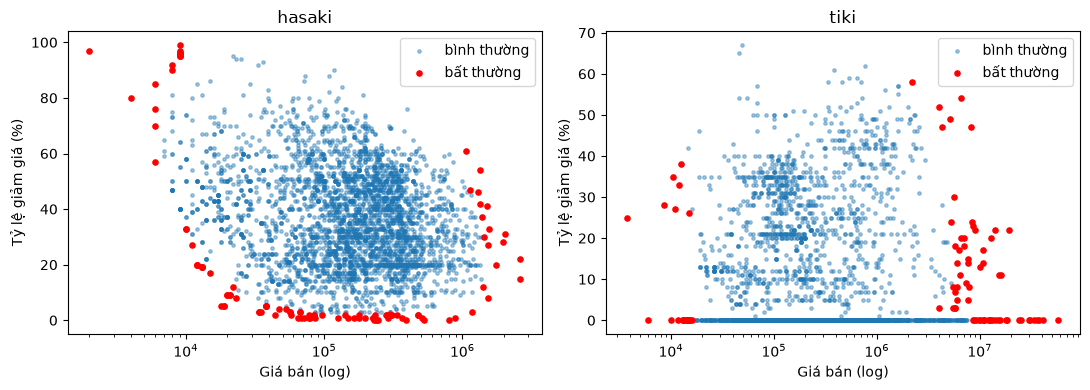

In [7]:
# 7. Xem mẫu sản phẩm bất thường và vẽ biểu đồ
cot = ["nguon", "ma_san_pham", "ten_san_pham", "gia_ban", "gia_goc", "ty_le_giam_gia", "anomaly_score", "ly_do"]
top = full[full.is_anomaly].sort_values("anomaly_score", ascending=False)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 45)
for src, g in top.groupby("nguon"):
    print(f"\nTop 8 bất thường - {src}:\n", g[cot].head(8).to_string(index=False))
top.groupby("nguon").head(20)[cot].to_csv(OUTPUT_DIR / "anomalies_top20_moi_san.csv", index=False, encoding="utf-8-sig")
print("\nLý do bị gắn cờ:\n", top.groupby(["nguon", "ly_do"]).size().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, (src, g) in zip(ax, full.groupby("nguon")):
    a_.scatter(g.loc[~g.is_anomaly, "gia_ban"], g.loc[~g.is_anomaly, "ty_le_giam_gia"], s=6, alpha=0.4, label="bình thường")
    a_.scatter(g.loc[g.is_anomaly, "gia_ban"], g.loc[g.is_anomaly, "ty_le_giam_gia"], s=14, color="red", label="bất thường")
    a_.set_xscale("log"); a_.set_title(src); a_.set_xlabel("Giá bán (log)"); a_.set_ylabel("Tỷ lệ giảm giá (%)"); a_.legend()
savefig(plt, "iforest_gia_vs_giam_gia")
plt.show()

In [8]:
# 8. Lưu mô hình, kết quả và chỉ số
joblib.dump({"models": models, "features": FEATURES, "version": "v1"}, MODELS_DIR / "iforest.pkl")
save_results("ml_anomalies", res.reset_index(drop=True))
save_metrics("isolation_forest",
             metrics={"kiem_tra_bat_hop_ly": kiem_tra,
                      "so_dong_thieu_gia_goc_khong_xet": int(df["thieu_gia_goc"].sum()),
                      "so_bat_thuong_moi_san": {k: int(v) for k, v in res.groupby("nguon")["is_anomaly"].sum().items()},
                      "jaccard_khi_them_so_luong_da_ban": float(jaccard),
                      "ty_le_trung_voi_iqr": float(ty_le_trung)},
             params={"features": FEATURES, "contamination": CONTAMINATION, "n_estimators": 300,
                     "huan_luyen": "rieng tung san, bo dong thieu gia goc", "random_state": 42},
             n_train=len(train_df))

[Lưu] ml_anomalies: 6945 dòng -> output/ml_anomalies.csv (chưa ghi Mongo)
[Lưu] metrics isolation_forest -> models/metrics.json (chưa ghi Mongo)
